# CPS 3830 Final Project: Midterm Notebook

> **Note:** This notebook contains **Tasks 1–3** of the project (Task 1: data loading, preprocessing and exploration; Task 2: feature analysis and dimensionality reduction; Task 3: modeling and evaluation with two baseline methods). Task 4 (the research-inspired method) will be added for the final report.

**Dataset:** MIND (Microsoft News Dataset), MIND-large training split, from https://msnews.github.io/

**Learning goal:** binary **classification**: given a user (their click history) and a candidate news article shown to them in an impression, predict whether the user **clicked** it.

Each row of the modeling table is one *(impression, candidate article)* pair; the target is `clicked` (1 = clicked, 0 = shown but skipped).

In [1]:
import csv, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler, OneHotEncoder, normalize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_DIR = "dataset MIND/MINDlarge_train"
SAMPLE_SEED = 42          # seed for the one-time user sampling below
MODEL_USER_FRAC = 0.007   # ~0.7% of users -> modeling sample
BG_USER_FRAC = 0.10       # disjoint ~10% of users -> "background" logs for popularity statistics
SEEDS = [0, 1, 2, 3, 4]   # the five fixed random seeds used for every experiment in Task 3 (and Task 4 later)
print("Seeds:", SEEDS)

Seeds: [0, 1, 2, 3, 4]


## Task 1: Data Loading, Preprocessing, and Initial Exploration

MIND has two main files:
- `news.tsv`: one row per article (id, category, subcategory, title, abstract, url, entity annotations).
- `behaviors.tsv`: one row per impression (impression id, user id, timestamp, the user's click **history**, and the list of articles shown with a `-1`/`-0` click label).

The full training split has ~2.23M impressions (1.37 GB), so we **sample by user**: users are hashed into buckets so that a ~0.7% user sample is used for modeling and a *disjoint* ~10% user sample ("background logs") is used only to compute article popularity statistics. Because the two samples share no users, popularity features never use the modeled user's own clicks.

In [2]:
news_cols = ["news_id", "category", "subcategory", "title", "abstract", "url",
             "title_entities", "abstract_entities"]
news = pd.read_csv(f"{DATA_DIR}/news.tsv", sep="\t", header=None, names=news_cols,
                   quoting=csv.QUOTE_NONE)
print("news shape:", news.shape)
news.head(3)

news shape: (101527, 8)


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N88753,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N45436,news,newsscienceandtechnology,Walmart Slashes Prices on Last-Generation iPads,Apple's new iPad releases bring big deals on l...,https://assets.msn.com/labs/mind/AABmf2I.html,"[{""Label"": ""IPad"", ""Type"": ""J"", ""WikidataId"": ...","[{""Label"": ""IPad"", ""Type"": ""J"", ""WikidataId"": ..."
2,N23144,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."


In [3]:
beh_cols = ["impression_id", "user_id", "time", "history", "impressions"]
t0 = time.time()
model_parts, bg_parts, n_total = [], [], 0
for chunk in pd.read_csv(f"{DATA_DIR}/behaviors.tsv", sep="\t", header=None, names=beh_cols,
                         quoting=csv.QUOTE_NONE, chunksize=250_000):
    n_total += len(chunk)
    # deterministic per-user bucket in [0, 1)
    u = (pd.util.hash_pandas_object(chunk["user_id"], index=False, hash_key=str(SAMPLE_SEED).zfill(16))
         % 100_000).to_numpy() / 100_000
    model_parts.append(chunk[u < MODEL_USER_FRAC])
    bg_parts.append(chunk[(u >= MODEL_USER_FRAC) & (u < MODEL_USER_FRAC + BG_USER_FRAC)])
beh = pd.concat(model_parts, ignore_index=True)
bg = pd.concat(bg_parts, ignore_index=True)
print(f"read {n_total:,} impressions in {time.time()-t0:.0f}s")
print("modeling impressions:", beh.shape, "| users:", beh.user_id.nunique())
print("background impressions:", bg.shape, "| users:", bg.user_id.nunique())
beh.head(3)

read 2,232,748 impressions in 11s
modeling impressions: (16130, 5) | users: 5130
background impressions: (222967, 5) | users: 71040


,impression_id,user_id,time,history,impressions
0,395,U155703,11/10/2019 6:59:11 PM,N62939 N56841 N89244 N5099 N110352 N47349 N124...,N125196-0 N94230-0 N100441-0 N39363-0 N46818-0...
1,651,U252105,11/13/2019 9:17:11 AM,N50108 N128909 N3435 N79285 N40587 N27352 N343...,N63391-0 N24430-0 N94220-0 N58449-0 N53474-0 N...
2,654,U585510,11/14/2019 8:48:50 AM,N66687 N72658 N14240 N40037 N46757 N98881 N966...,N44953-0 N25016-0 N56873-0 N40040-0 N62017-0 N...


### Shape, feature names and missing values

In [4]:
def missing_report(df, name):
    r = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_missing": df.isna().sum(),
                      "pct_missing": (df.isna().mean() * 100).round(2)})
    print(f"{name}: shape={df.shape}")
    return r

display(missing_report(news, "news"))
display(missing_report(beh, "behaviors (modeling sample)"))

news: shape=(101527, 8)


,dtype,n_missing,pct_missing
news_id,str,0,0.00
category,str,0,0.00
subcategory,str,0,0.00
title,str,0,0.00
abstract,str,5415,5.33
url,str,0,0.00
title_entities,str,0,0.00
abstract_entities,str,0,0.00


behaviors (modeling sample): shape=(16130, 5)


,dtype,n_missing,pct_missing
impression_id,int64,0,0.00
user_id,str,0,0.00
time,str,0,0.00
history,str,350,2.17
impressions,str,0,0.00


### Building the modeling table (one row per impression × candidate)
Each `impressions` entry looks like `N12345-1` (clicked) or `N12345-0` (not clicked). We explode these into rows; the suffix becomes the **target label `clicked`**.

In [5]:
beh["time"] = pd.to_datetime(beh["time"], format="%m/%d/%Y %I:%M:%S %p")
beh["imp_row"] = np.arange(len(beh))           # row index of the impression (used for history matrices)
beh["imp_size"] = beh["impressions"].str.count(" ") + 1

rows = beh[["imp_row", "impression_id", "user_id", "time", "imp_size", "impressions"]].copy()
rows["cand"] = rows["impressions"].str.split()
rows = rows.drop(columns="impressions").explode("cand", ignore_index=True)
rows["news_id"] = rows["cand"].str[:-2]
rows["clicked"] = rows["cand"].str[-1].astype(int)
rows = rows.drop(columns="cand")
print("modeling rows:", rows.shape)
print("target label distribution:")
print(rows["clicked"].value_counts().rename({0: "not clicked (0)", 1: "clicked (1)"}))
print(f"click rate = {rows['clicked'].mean():.4f}")

modeling rows: (601564, 7)
target label distribution:
clicked
not clicked (0)    577276
clicked (1)         24288
Name: count, dtype: int64
click rate = 0.0404


### Feature engineering
Raw MIND rows are ids and text, so we engineer numeric features (TF-IDF is used for text, as suggested in the project description):

| Feature | Meaning |
|---|---|
| `category` | candidate article category (one-hot encoded) |
| `title_len`, `abstract_len` | words in the title / abstract |
| `n_title_entities` | number of Wikidata entities linked in the title |
| `hist_len` | number of articles in the user's click history |
| `imp_size` | number of articles shown in the impression |
| `hour` | hour of day of the impression |
| `pop_shows`, `pop_ctr` | how often the article was shown / its smoothed click-through rate in the **background** logs |
| `pop_hist` | how often the article appears in background users' click histories |
| `cat_affinity`, `subcat_affinity` | share of the user's history in the candidate's category / subcategory |
| `title_sim` | cosine similarity between the candidate title's TF-IDF vector and the user's mean history TF-IDF vector |

In [6]:
# --- article-level features ---
news["abstract"] = news["abstract"].fillna("")
news["title_len"] = news["title"].str.split().str.len()
news["abstract_len"] = news["abstract"].str.split().str.len()
news["n_title_entities"] = news["title_entities"].fillna("").str.count('"Label"')
news_idx = pd.Series(np.arange(len(news)), index=news["news_id"])

# --- popularity statistics from the disjoint background users ---
bg_exp = bg["impressions"].str.split().explode()
bg_clicks = pd.DataFrame({"news_id": bg_exp.str[:-2].values, "clicked": bg_exp.str[-1].astype(int).values})
pop = bg_clicks.groupby("news_id")["clicked"].agg(clicks="sum", shows="count")
global_ctr = bg_clicks["clicked"].mean()
ALPHA = 20  # Bayesian smoothing toward the global CTR for rarely shown articles
pop["pop_ctr"] = (pop["clicks"] + ALPHA * global_ctr) / (pop["shows"] + ALPHA)
hist_pop = bg["history"].dropna().str.split().explode().value_counts()
news["pop_shows"] = news["news_id"].map(pop["shows"]).fillna(0)
news["pop_ctr"] = news["news_id"].map(pop["pop_ctr"]).fillna(global_ctr)
news["pop_hist"] = news["news_id"].map(hist_pop).fillna(0)
del bg_exp, bg_clicks

# --- user history matrix H (impressions x articles) ---
hist_lists = beh["history"].fillna("").str.split()
indptr, indices = [0], []
for h in hist_lists:
    indices.extend(news_idx.reindex(h).dropna().astype(int).tolist())
    indptr.append(len(indices))
H = sparse.csr_matrix((np.ones(len(indices)), indices, indptr), shape=(len(beh), len(news)))
beh["hist_len"] = np.diff(H.indptr)

# category / subcategory affinity
def affinity(col):
    codes, uniques = pd.factorize(news[col])
    C = sparse.csr_matrix((np.ones(len(news)), (np.arange(len(news)), codes)), shape=(len(news), len(uniques)))
    A = (H @ C).toarray() / np.maximum(beh["hist_len"].to_numpy(), 1)[:, None]
    return A, codes

# TF-IDF of titles and user profile vectors
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_features=30000)
X_title = tfidf.fit_transform(news["title"].fillna(""))
U = normalize(H @ X_title)          # mean of history title vectors, L2-normalized
print("TF-IDF vocabulary:", X_title.shape)

# --- join everything onto the rows ---
rows["n_idx"] = news_idx.reindex(rows["news_id"]).to_numpy()
assert rows["n_idx"].notna().all()
rows["n_idx"] = rows["n_idx"].astype(int)
n_i, i_i = rows["n_idx"].to_numpy(), rows["imp_row"].to_numpy()

for c in ["category", "subcategory", "title_len", "abstract_len", "n_title_entities",
          "pop_shows", "pop_ctr", "pop_hist"]:
    rows[c] = news[c].to_numpy()[n_i]
rows["hist_len"] = beh["hist_len"].to_numpy()[i_i]
rows["hour"] = rows["time"].dt.hour

for col, name in [("category", "cat_affinity"), ("subcategory", "subcat_affinity")]:
    A, codes = affinity(col)
    rows[name] = A[i_i, codes[n_i]]

sims = np.empty(len(rows))
for s in range(0, len(rows), 50_000):
    e = s + 50_000
    sims[s:e] = np.asarray(X_title[n_i[s:e]].multiply(U[i_i[s:e]]).sum(axis=1)).ravel()
rows["title_sim"] = sims
print("feature table:", rows.shape)
rows.head()

TF-IDF vocabulary: (101527, 20039)


feature table: (601564, 21)


,imp_row,impression_id,user_id,time,imp_size,news_id,clicked,n_idx,category,subcategory,title_len,abstract_len,n_title_entities,pop_shows,pop_ctr,pop_hist,hist_len,hour,cat_affinity,subcat_affinity,title_sim
0,0,395,U155703,2019-11-10 18:59:11,115,N125196,0,35666,finance,finance-retirement,9,19,1,2666.0,0.020034,199.0,42,18,0.238095,0.02381,0.044673
1,0,395,U155703,2019-11-10 18:59:11,115,N94230,0,35586,finance,finance-saving-investing,13,35,0,4673.0,0.019990,853.0,42,18,0.238095,0.00000,0.035195
2,0,395,U155703,2019-11-10 18:59:11,115,N100441,0,94530,news,newsus,11,22,1,4482.0,0.036830,0.0,42,18,0.023810,0.02381,0.000000
3,0,395,U155703,2019-11-10 18:59:11,115,N39363,0,90746,lifestyle,lifestyleroyals,15,21,1,2157.0,0.046767,0.0,42,18,0.190476,0.00000,0.045917
4,0,395,U155703,2019-11-10 18:59:11,115,N46818,0,85498,lifestyle,lifestylehomeandgarden,10,54,0,2173.0,0.028186,275.0,42,18,0.190476,0.02381,0.049727


### Exploratory plots

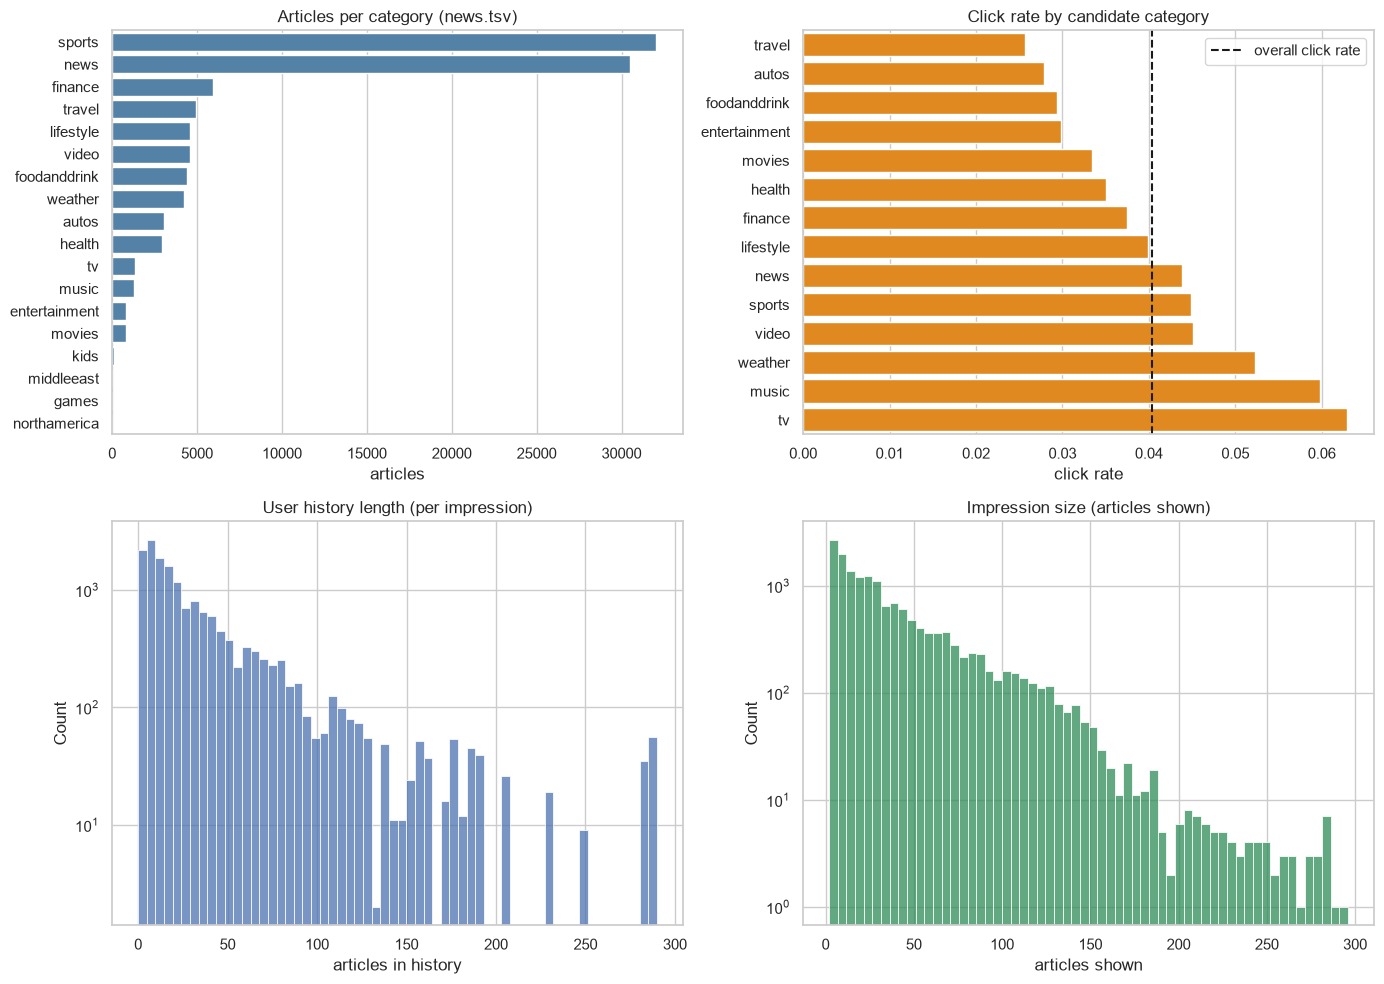

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cat_counts = news["category"].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0, 0], color="steelblue")
axes[0, 0].set(title="Articles per category (news.tsv)", xlabel="articles", ylabel="")

ctr_cat = rows.groupby("category")["clicked"].agg(["mean", "count"]).query("count >= 500").sort_values("mean")
sns.barplot(x=ctr_cat["mean"], y=ctr_cat.index, ax=axes[0, 1], color="darkorange")
axes[0, 1].axvline(rows["clicked"].mean(), color="k", ls="--", label="overall click rate")
axes[0, 1].set(title="Click rate by candidate category", xlabel="click rate", ylabel="")
axes[0, 1].legend()

sns.histplot(beh["hist_len"], bins=60, ax=axes[1, 0])
axes[1, 0].set(title="User history length (per impression)", xlabel="articles in history", yscale="log")

sns.histplot(beh["imp_size"], bins=60, ax=axes[1, 1], color="seagreen")
axes[1, 1].set(title="Impression size (articles shown)", xlabel="articles shown", yscale="log")
plt.tight_layout(); plt.show()

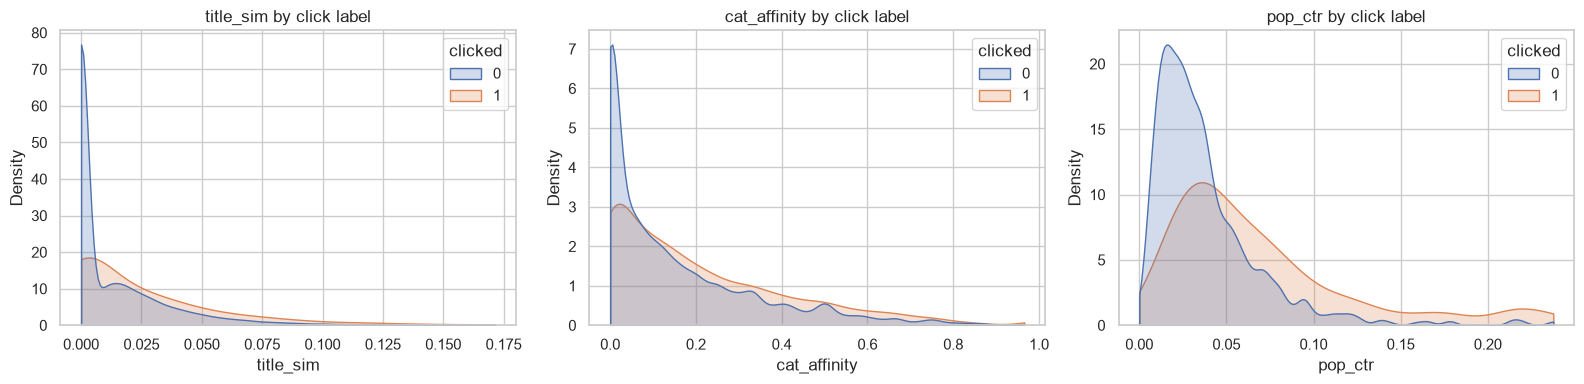

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["title_sim", "cat_affinity", "pop_ctr"]):
    sns.kdeplot(data=rows.sample(100_000, random_state=0), x=col, hue="clicked",
                common_norm=False, fill=True, ax=ax, clip=(0, rows[col].quantile(0.995)))
    ax.set_title(f"{col} by click label")
plt.tight_layout(); plt.show()

### Preprocessing
- **Missing values:** empty abstracts are filled with `""` (so `abstract_len` = 0); users with no history get `hist_len = 0`, and their affinity / similarity features are 0.
- **Outlier handling and skew:** count features (`hist_len`, `imp_size`, `pop_shows`, `pop_hist`, `title_len`, `abstract_len`) are heavily right-skewed, so they are clipped at their 99.5th percentile and `log1p`-transformed.
- **Encoding:** `category` is one-hot encoded (categories with < 0.1% of rows are grouped as `other`). `subcategory` (~270 values) is represented through `subcat_affinity` rather than one-hot.
- **Normalization:** all numeric features are standardized with `StandardScaler`. The scaler is part of the model pipeline and is **fit on the training split only** in every run, so no test statistics leak into training.

In [9]:
SKEWED = ["hist_len", "imp_size", "pop_shows", "pop_hist", "title_len", "abstract_len"]
for c in SKEWED:
    rows[c] = np.log1p(rows[c].clip(upper=rows[c].quantile(0.995)))

rare = rows["category"].value_counts(normalize=True) < 0.001
rows["category"] = rows["category"].where(~rows["category"].map(rare), "other")

NUM_FEATS = ["title_len", "abstract_len", "n_title_entities", "hist_len", "imp_size", "hour",
             "pop_shows", "pop_ctr", "pop_hist", "cat_affinity", "subcat_affinity", "title_sim"]
CAT_FEATS = ["category"]
TARGET = "clicked"

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS),
    ])

rows[NUM_FEATS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
title_len,601564.0,2.438,0.295,1.099,2.303,2.485,2.639,3.258
abstract_len,601564.0,2.969,0.889,0.000,2.639,3.091,3.434,4.605
n_title_entities,601564.0,0.981,0.954,0.000,0.000,1.000,2.000,7.000
hist_len,601564.0,3.058,1.104,0.000,2.303,3.091,3.871,5.434
imp_size,601564.0,4.090,0.798,1.099,3.611,4.220,4.691,5.631
hour,601564.0,10.787,4.881,0.000,7.000,10.000,14.000,23.000
pop_shows,601564.0,8.287,1.390,0.000,7.704,8.562,9.263,10.224
pop_ctr,601564.0,0.041,0.039,0.001,0.017,0.030,0.050,0.425
pop_hist,601564.0,1.122,2.362,0.000,0.000,0.000,0.000,8.782
cat_affinity,601564.0,0.155,0.193,0.000,0.000,0.083,0.238,1.000


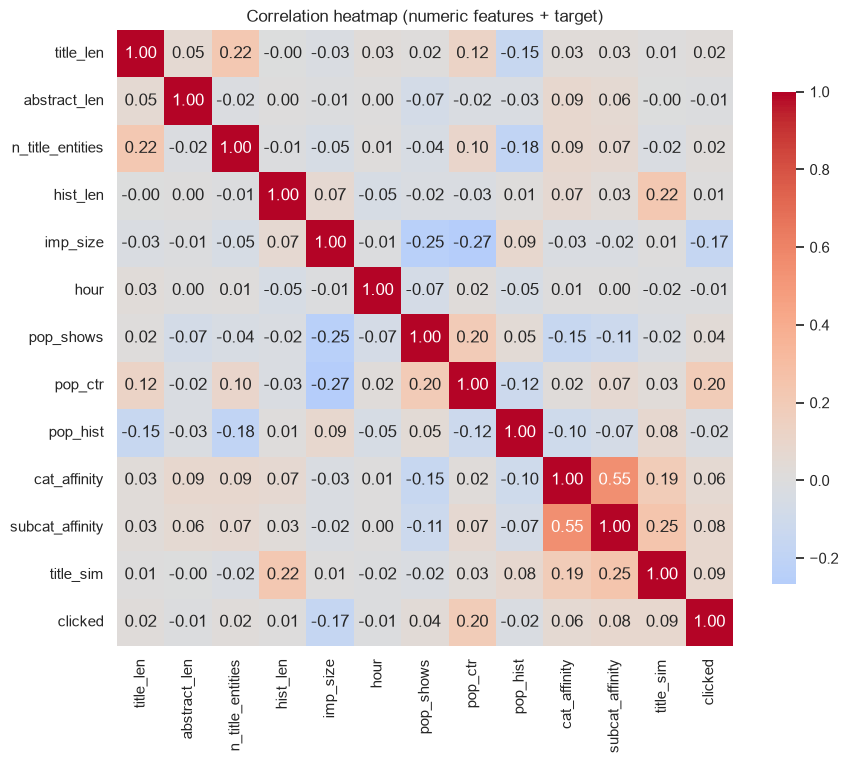

Correlation with target:
pop_ctr             0.196
imp_size           -0.167
title_sim           0.088
subcat_affinity     0.082
cat_affinity        0.058
pop_shows           0.039
pop_hist           -0.024
title_len           0.022
n_title_entities    0.021
hist_len            0.009
abstract_len       -0.007
hour               -0.006
Name: clicked, dtype: float64


In [10]:
corr = rows[NUM_FEATS + [TARGET]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap (numeric features + target)"); plt.show()
print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

### Task 1 observations

- **Size and target:** the user sample contains 16,130 impressions from 5,130 users, which explode into **601,564 (impression, candidate) rows** with 12 numeric features plus a one-hot `category` (27 model inputs). The target is highly **imbalanced**: only **4.04%** of shown articles were clicked (24,288 clicks vs 577,276 skips). Accuracy alone would be misleading, because predicting "not clicked" everywhere already gives ~96% accuracy.
- **Missing values:** 5.3% of articles have no abstract, and 2.2% of impressions come from users with an empty click history (cold-start users). No other columns have missing values.
- **Distributions:** `sports` and `news` together make up ~61% of articles. History length and impression size are long-tailed (some impressions show almost 300 articles), which motivated clipping plus `log1p`.
- **Click rate by category** ranges from ~2.6% (travel) to ~6.3% (tv) and ~6.0% (music), so category carries some signal.
- **Features most correlated with the target:** article popularity `pop_ctr` (r = 0.20) is strongest. `imp_size` is negatively correlated (r = -0.17): an impression usually has only 1–2 clicks, so the more articles are shown, the lower each one's chance of being clicked. The personalization features `title_sim` (0.09), `subcat_affinity` (0.08) and `cat_affinity` (0.06) are next. Clicked articles have about **twice** the mean `title_sim`, `subcat_affinity` and `pop_ctr` of skipped ones.
- **Weak features:** hour of day, abstract length and history length have almost no linear relationship with clicking. `pop_hist` is slightly *negative*, because histories mostly contain older articles while candidates are fresh news, so a fresh article rarely appears in any history.

## Task 2: Feature Analysis and Dimensionality Reduction

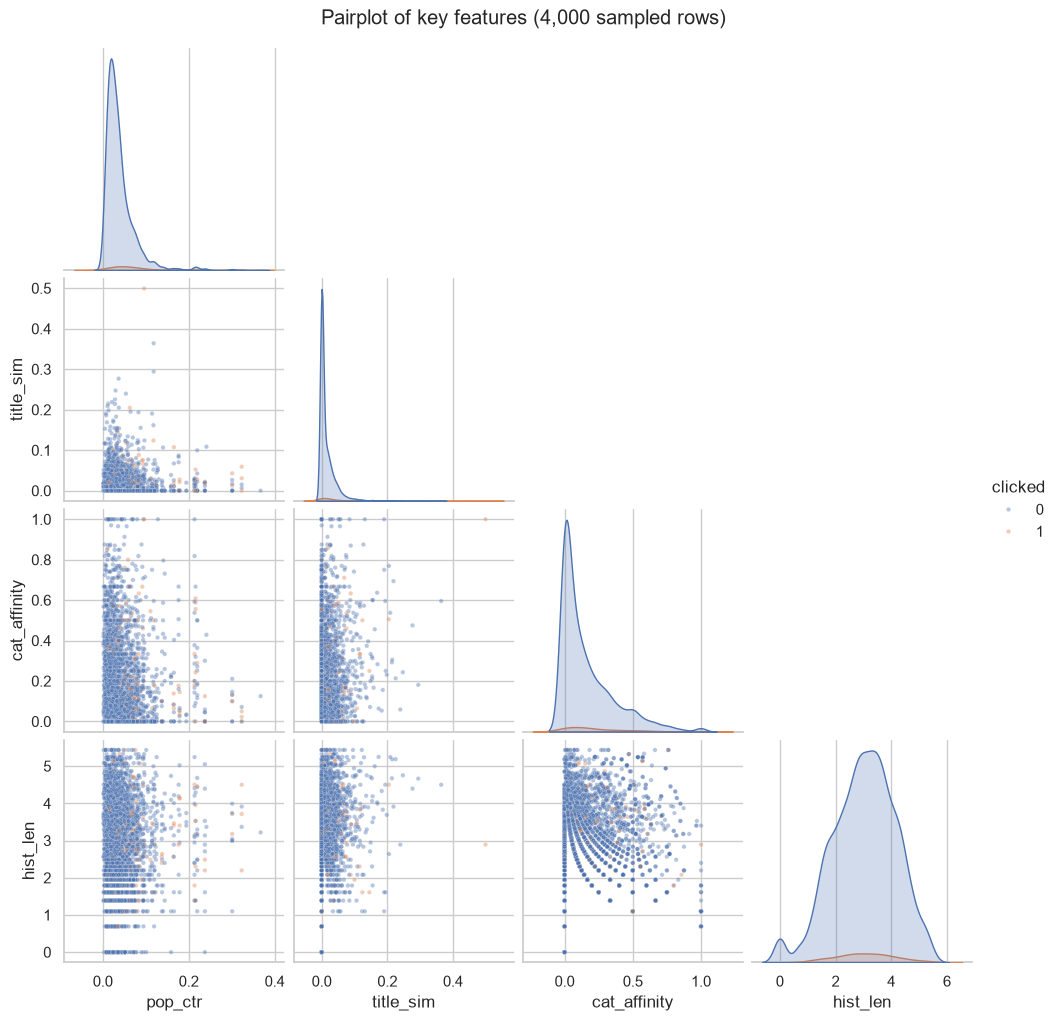

clicked,mean | not clicked,mean | clicked
title_len,2.437,2.470
abstract_len,2.970,2.940
n_title_entities,0.977,1.076
hist_len,3.056,3.107
imp_size,4.117,3.439
hour,10.793,10.638
pop_shows,8.275,8.551
pop_ctr,0.039,0.078
pop_hist,1.134,0.848
cat_affinity,0.153,0.210


In [11]:
# pairwise relationships of the most informative features (sampled for readability)
pair_sample = rows.sample(4000, random_state=0)
g = sns.pairplot(pair_sample, vars=["pop_ctr", "title_sim", "cat_affinity", "hist_len"],
                 hue=TARGET, plot_kws={"alpha": .4, "s": 10}, diag_kind="kde", corner=True)
g.fig.suptitle("Pairplot of key features (4,000 sampled rows)", y=1.02); plt.show()

rows.groupby(TARGET)[NUM_FEATS].mean().T.round(3).rename(columns={0: "mean | not clicked", 1: "mean | clicked"})

### PCA on the full preprocessed feature space

feature dimension: 27


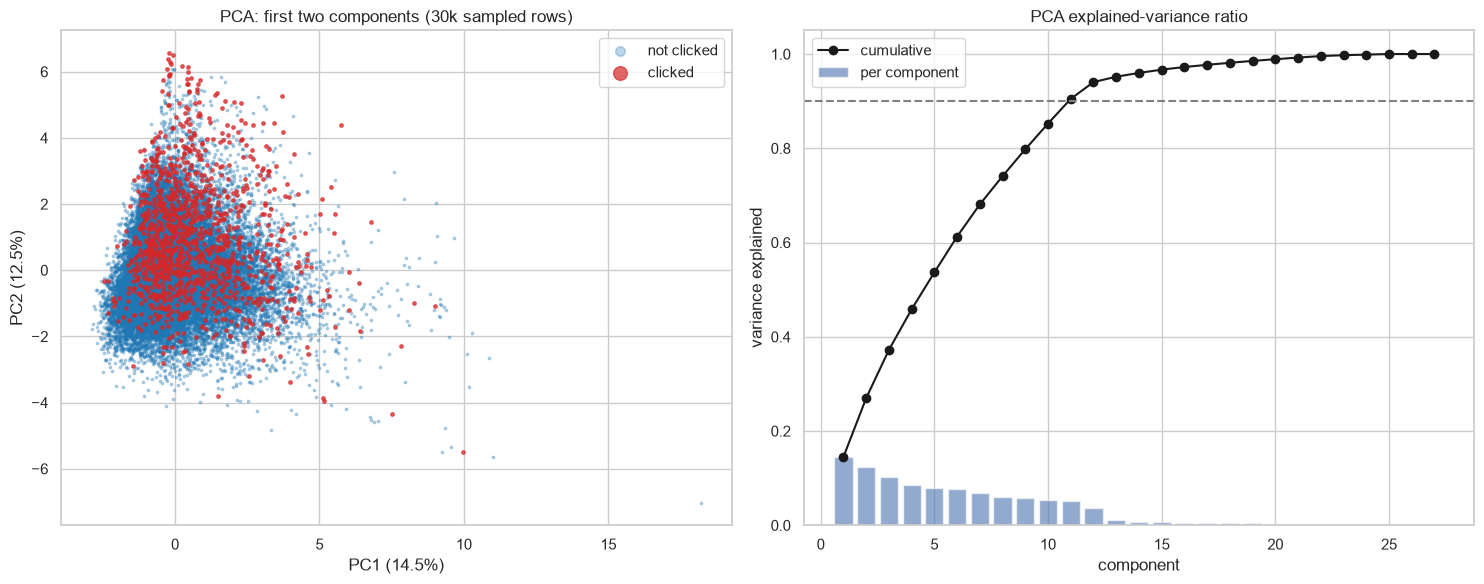

components needed for 90% variance: 11


,PC1,PC2,PC3
cat_affinity,0.589,-0.092,0.055
subcat_affinity,0.572,-0.083,0.133
title_sim,0.311,-0.178,0.409
n_title_entities,0.214,0.300,-0.345
pop_hist,-0.210,-0.315,0.350
pop_shows,-0.192,0.376,0.449
title_len,0.156,0.308,-0.282
category_news,0.147,0.019,-0.025
abstract_len,0.138,-0.041,-0.137
hist_len,0.135,-0.193,0.244


In [12]:
prep = make_preprocessor()
Z = prep.fit_transform(rows[NUM_FEATS + CAT_FEATS])
feat_names = NUM_FEATS + list(prep.named_transformers_["cat"].get_feature_names_out(CAT_FEATS))
pca = PCA(random_state=0).fit(Z)
print("feature dimension:", Z.shape[1])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# 2-D embedding colored by label (clicked points drawn on top)
idx = np.random.default_rng(0).choice(len(Z), 30_000, replace=False)
P = pca.transform(Z[idx])[:, :2]
y_s = rows[TARGET].to_numpy()[idx]
axes[0].scatter(P[y_s == 0, 0], P[y_s == 0, 1], s=3, alpha=.3, label="not clicked", c="tab:blue")
axes[0].scatter(P[y_s == 1, 0], P[y_s == 1, 1], s=6, alpha=.7, label="clicked", c="tab:red")
axes[0].set(title="PCA: first two components (30k sampled rows)",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[0].legend(markerscale=4)

cum = np.cumsum(pca.explained_variance_ratio_)
axes[1].bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, alpha=.6, label="per component")
axes[1].plot(range(1, len(cum) + 1), cum, "o-", c="k", label="cumulative")
axes[1].axhline(0.9, ls="--", c="gray")
axes[1].set(title="PCA explained-variance ratio", xlabel="component", ylabel="variance explained")
axes[1].legend(); plt.tight_layout(); plt.show()
print("components needed for 90% variance:", int(np.searchsorted(cum, 0.9) + 1))

loadings = pd.DataFrame(pca.components_[:3].T, index=feat_names, columns=["PC1", "PC2", "PC3"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(10).round(3)

### t-SNE of article titles (TF-IDF → SVD → t-SNE), colored by category
The behavioral features above are low-dimensional; the article *text* is where the high-dimensional structure is. We embed 4,000 articles from the 8 largest categories.

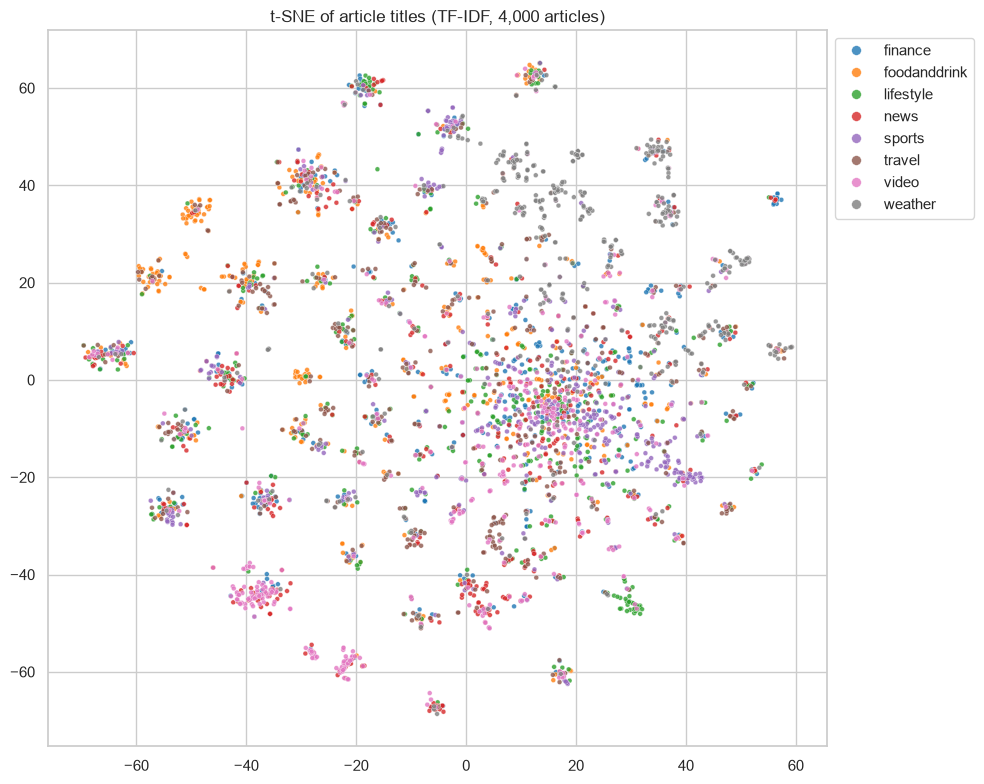

In [13]:
top8 = news["category"].value_counts().index[:8]
sub = news[news["category"].isin(top8)].groupby("category").sample(500, random_state=0)
X_sub = X_title[news_idx[sub["news_id"]].to_numpy()]
X_svd = TruncatedSVD(n_components=50, random_state=0).fit_transform(X_sub)
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X_svd)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=sub["category"].to_numpy(), s=12, alpha=.8, palette="tab10")
plt.title("t-SNE of article titles (TF-IDF, 4,000 articles)"); plt.legend(markerscale=2, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

### Task 2 observations

- **Feature relationships:** most features are only weakly correlated with each other. The strongest pairs are `cat_affinity`–`subcat_affinity` and `pop_shows`–`pop_hist`, which is expected because each pair measures related ideas (topic match at two granularities, and two kinds of popularity).
- **PCA:** variance is spread fairly evenly. PC1 explains only 14.5% and PC2 12.5%, and **11 components are needed to keep 90%** of the variance, so the features are not very redundant. The 16 one-hot category columns add very little variance after the first ~12 components. PC1 is essentially a "personal relevance" axis (`cat_affinity`, `subcat_affinity` and `title_sim` load at +0.59, +0.57 and +0.31). PC2 mixes popularity and title properties.
- **2-D embedding:** clicked points (red) are spread through the same region as skipped ones, with **no clean separation**. They are only mildly shifted toward positive PC1/PC2 (more personally relevant and more popular articles), and some outliers stretch far along PC1 (users whose history is concentrated in one topic). Clicks are therefore not linearly separable in a few dimensions, which suggests (a) a linear model will hit a ceiling and a non-linear model such as a Random Forest may help, and (b) we should keep all features rather than training on only 2–3 PCs.
- **t-SNE of article titles:** TF-IDF title vectors form many small, tight clusters, for example a large `weather` region, `foodanddrink` and `video` islands, and mixed `news`/`travel`/`lifestyle` groups. These are mostly story- or keyword-level clusters (the same event covered several times) rather than one blob per category, and there is a large mixed center of generic headlines. Article text therefore carries finer-grained topic structure than the 18 categories. This motivates the text-similarity feature here, and richer text representations (e.g., sentence embeddings) as a direction for Task 4.

## Task 3: Modeling and Evaluation

**Goal:** binary classification of `clicked`.

**Method 1:** Logistic Regression. **Method 2:** Random Forest.

**Experimental protocol**
- Five fixed seeds: **`SEEDS = [0, 1, 2, 3, 4]`**.
- For each seed, the data is split 80/20 into train/test **by user** (`GroupShuffleSplit`), so no user appears in both train and test. Both methods use exactly the same split for a given seed, and the same seed is used for model randomness (Random Forest bootstrap).
- Only ~4% of rows are clicks, so both models use `class_weight="balanced"` so that predictions at the default 0.5 threshold are meaningful for precision/recall/F1.
- **Main metric: ROC-AUC.** We also report accuracy, precision, recall, F1, and *mean impression AUC* (AUC computed within each impression and averaged, the official MIND leaderboard metric).

In [14]:
X_all = rows[NUM_FEATS + CAT_FEATS]
y_all = rows[TARGET].to_numpy()
groups = rows["user_id"].to_numpy()
imp_ids = rows["impression_id"].to_numpy()

def split_for_seed(seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    return next(gss.split(X_all, y_all, groups))

def make_lr(C=1.0, seed=0):
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=seed))])

def make_rf(max_depth=None, min_samples_leaf=1, seed=0):
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", RandomForestClassifier(n_estimators=100, max_depth=max_depth,
                                                    min_samples_leaf=min_samples_leaf, max_samples=0.3,
                                                    class_weight="balanced_subsample", n_jobs=-1,
                                                    random_state=seed))])

def mean_impression_auc(imp, y, p):
    d = pd.DataFrame({"imp": imp, "y": y, "p": p})
    aucs = [roc_auc_score(g["y"], g["p"]) for _, g in d.groupby("imp") if 0 < g["y"].sum() < len(g)]
    return float(np.mean(aucs))

def evaluate(y, p, imp):
    pred = (p >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y, p), "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "ImpressionAUC": mean_impression_auc(imp, y, p)}

### Hyperparameter tuning
Tuning uses **only the training portion of seed 0**, which is further split 80/20 by user into train/validation. The test sets are never used for tuning. Hyperparameters are selected by validation AUC.

tuning took 47s
Best LR: C=0.01 | Best RF: max_depth=16, min_samples_leaf=50


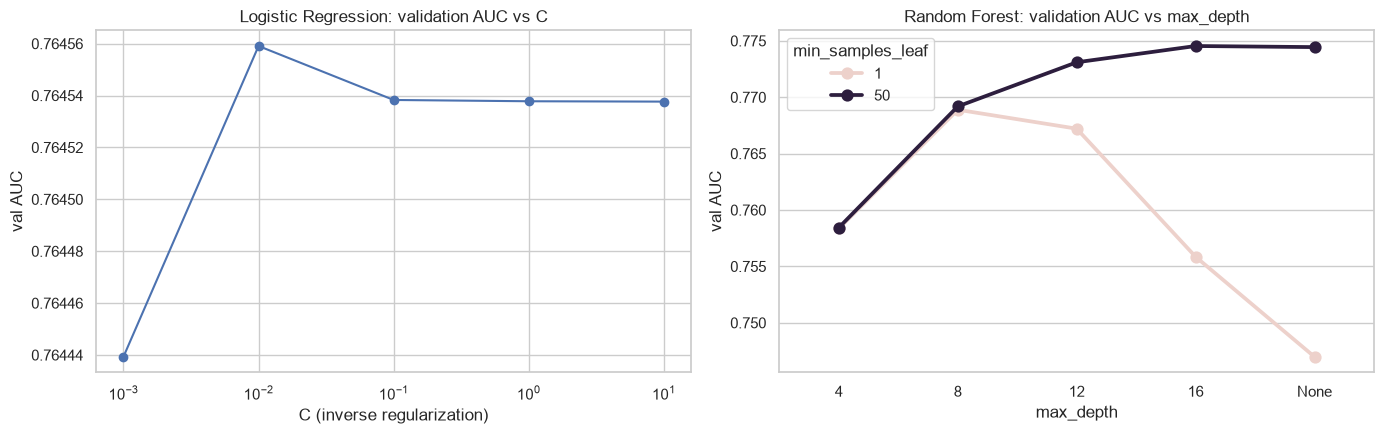

,C,val_AUC
0,0.001,0.7644
1,0.010,0.7646
2,0.100,0.7645
3,1.000,0.7645
4,10.000,0.7645


,max_depth,min_samples_leaf,val_AUC
0,4,1,0.7584
1,4,50,0.7584
2,8,1,0.7689
3,8,50,0.7692
4,12,1,0.7672
5,12,50,0.7731
6,16,1,0.7559
7,16,50,0.7745
8,None,1,0.7470
9,None,50,0.7744


In [15]:
tr0, _ = split_for_seed(SEEDS[0])
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEEDS[0])
a, b = next(gss_val.split(tr0, groups=groups[tr0]))
tr_i, va_i = tr0[a], tr0[b]

t0 = time.time()
lr_grid = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    m = make_lr(C=C).fit(X_all.iloc[tr_i], y_all[tr_i])
    lr_grid.append({"C": C, "val_AUC": roc_auc_score(y_all[va_i], m.predict_proba(X_all.iloc[va_i])[:, 1])})
lr_grid = pd.DataFrame(lr_grid)

rf_grid = []
for depth in [4, 8, 12, 16, None]:
    for leaf in [1, 50]:
        m = make_rf(max_depth=depth, min_samples_leaf=leaf).fit(X_all.iloc[tr_i], y_all[tr_i])
        rf_grid.append({"max_depth": str(depth), "min_samples_leaf": leaf,
                        "val_AUC": roc_auc_score(y_all[va_i], m.predict_proba(X_all.iloc[va_i])[:, 1])})
rf_grid = pd.DataFrame(rf_grid)
print(f"tuning took {time.time()-t0:.0f}s")

best_lr = lr_grid.loc[lr_grid["val_AUC"].idxmax()]
best_rf = rf_grid.loc[rf_grid["val_AUC"].idxmax()]
BEST_C = float(best_lr["C"])
BEST_DEPTH = None if best_rf["max_depth"] == "None" else int(best_rf["max_depth"])
BEST_LEAF = int(best_rf["min_samples_leaf"])
print(f"Best LR: C={BEST_C} | Best RF: max_depth={BEST_DEPTH}, min_samples_leaf={BEST_LEAF}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].semilogx(lr_grid["C"], lr_grid["val_AUC"], "o-")
axes[0].set(title="Logistic Regression: validation AUC vs C", xlabel="C (inverse regularization)", ylabel="val AUC")
sns.pointplot(data=rf_grid, x="max_depth", y="val_AUC", hue="min_samples_leaf", ax=axes[1])
axes[1].set(title="Random Forest: validation AUC vs max_depth", ylabel="val AUC")
plt.tight_layout(); plt.show()
display(lr_grid.round(4)); display(rf_grid.round(4))

### Five-seed evaluation (Method 1 vs Method 2, matched splits)

In [16]:
results, roc_store, last_models = [], {}, {}
t0 = time.time()
for seed in SEEDS:
    tr, te = split_for_seed(seed)
    for name, model in [("LogisticRegression", make_lr(C=BEST_C, seed=seed)),
                        ("RandomForest", make_rf(BEST_DEPTH, BEST_LEAF, seed=seed))]:
        model.fit(X_all.iloc[tr], y_all[tr])
        p = model.predict_proba(X_all.iloc[te])[:, 1]
        results.append({"seed": seed, "method": name, **evaluate(y_all[te], p, imp_ids[te])})
        roc_store[(name, seed)] = (y_all[te], p)
        if seed == SEEDS[0]:
            last_models[name] = model
print(f"5-seed evaluation took {time.time()-t0:.0f}s")
res = pd.DataFrame(results)
res.round(4)

5-seed evaluation took 75s


,seed,method,AUC,Accuracy,Precision,Recall,F1,ImpressionAUC
0,0,LogisticRegression,0.7755,0.7545,0.0998,0.6448,0.1728,0.7166
1,0,RandomForest,0.7908,0.8255,0.1269,0.5762,0.2080,0.7331
2,1,LogisticRegression,0.7726,0.7530,0.1012,0.6416,0.1748,0.7153
3,1,RandomForest,0.7869,0.8239,0.1260,0.5594,0.2057,0.7257
4,2,LogisticRegression,0.7769,0.7527,0.1026,0.6509,0.1772,0.7109
5,2,RandomForest,0.7890,0.8230,0.1259,0.5594,0.2055,0.7251
6,3,LogisticRegression,0.7767,0.7697,0.1005,0.6292,0.1733,0.7075
7,3,RandomForest,0.7885,0.8347,0.1239,0.5450,0.2019,0.7171
8,4,LogisticRegression,0.7734,0.7476,0.1023,0.6532,0.1769,0.7069
9,4,RandomForest,0.7843,0.8172,0.1250,0.5669,0.2048,0.7155


In [17]:
METRICS = ["AUC", "ImpressionAUC", "F1", "Precision", "Recall", "Accuracy"]
summary = res.groupby("method")[METRICS].agg(["mean", "std"])
pretty = pd.DataFrame({m: summary[m]["mean"].map("{:.4f}".format) + " ± " + summary[m]["std"].map("{:.4f}".format)
                       for m in METRICS})
print("Mean ± std over seeds", SEEDS)
pretty

Mean ± std over seeds [0, 1, 2, 3, 4]


,AUC,ImpressionAUC,F1,Precision,Recall,Accuracy
method,,,,,,
LogisticRegression,0.7750 ± 0.0019,0.7114 ± 0.0044,0.1750 ± 0.0020,0.1013 ± 0.0012,0.6440 ± 0.0094,0.7555 ± 0.0083
RandomForest,0.7879 ± 0.0024,0.7233 ± 0.0071,0.2052 ± 0.0022,0.1255 ± 0.0012,0.5614 ± 0.0114,0.8249 ± 0.0063


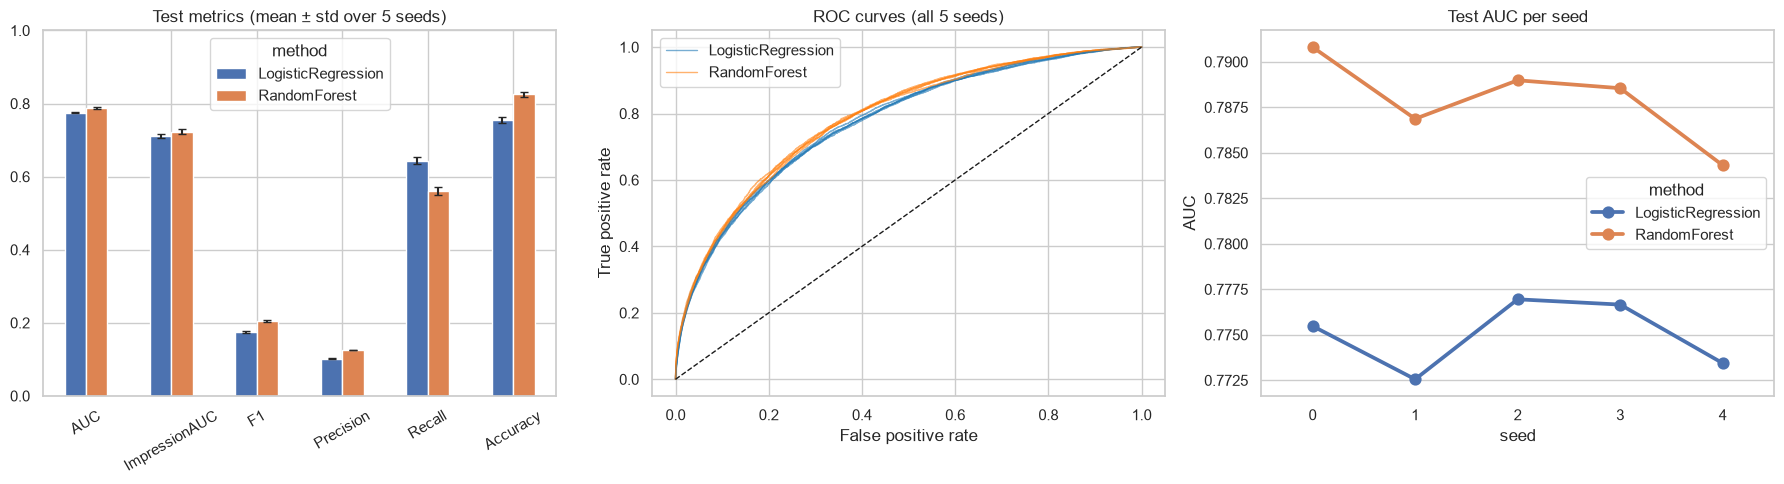

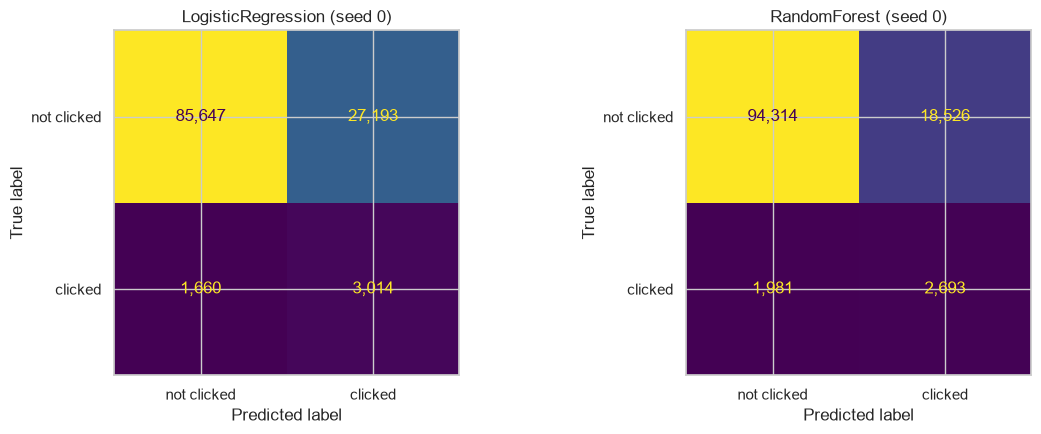

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# bar chart mean ± std
m = res.groupby("method")[METRICS].mean().T
s = res.groupby("method")[METRICS].std().T
m.plot.bar(yerr=s, ax=axes[0], capsize=3, rot=30)
axes[0].set(title="Test metrics (mean ± std over 5 seeds)", ylim=(0, 1))

# ROC curves for all seeds
for (name, seed), (yt, p) in roc_store.items():
    fpr, tpr, _ = roc_curve(yt, p)
    axes[1].plot(fpr, tpr, c="tab:blue" if name == "LogisticRegression" else "tab:orange", alpha=.6, lw=1,
                 label=name if seed == SEEDS[0] else None)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(title="ROC curves (all 5 seeds)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend()

# per-seed AUC
sns.pointplot(data=res, x="seed", y="AUC", hue="method", ax=axes[2])
axes[2].set(title="Test AUC per seed")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["LogisticRegression", "RandomForest"]):
    yt, p = roc_store[(name, SEEDS[0])]
    ConfusionMatrixDisplay(confusion_matrix(yt, (p >= .5).astype(int)), display_labels=["not clicked", "clicked"]).plot(
        ax=ax, values_format=",d", colorbar=False)
    ax.set_title(f"{name} (seed {SEEDS[0]})")
plt.tight_layout(); plt.show()

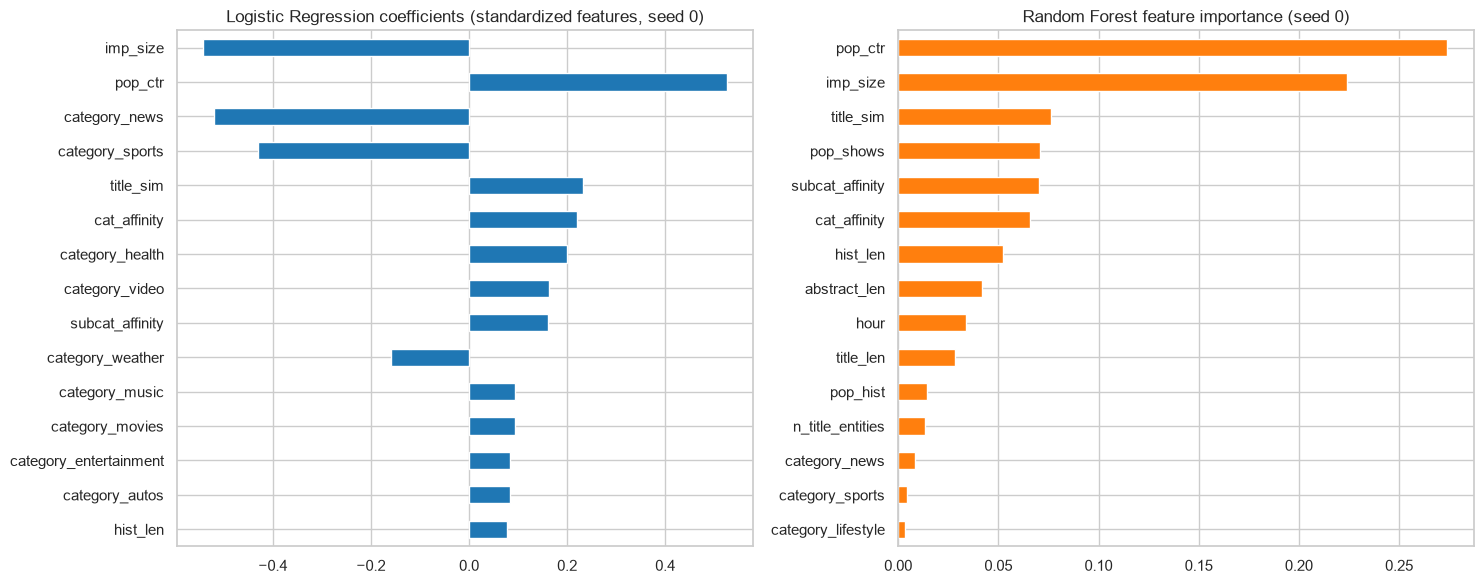

In [19]:
names_out = last_models["LogisticRegression"].named_steps["prep"].get_feature_names_out()
names_out = [n.split("__", 1)[1] for n in names_out]
coef = pd.Series(last_models["LogisticRegression"].named_steps["clf"].coef_[0], index=names_out)
imp = pd.Series(last_models["RandomForest"].named_steps["clf"].feature_importances_, index=names_out)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
coef.reindex(coef.abs().sort_values().index).tail(15).plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Logistic Regression coefficients (standardized features, seed 0)")
imp.sort_values().tail(15).plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_title("Random Forest feature importance (seed 0)")
plt.tight_layout(); plt.show()

### Task 3 discussion

**Hyperparameter tuning (validation AUC, seed-0 training data only)**
- *Logistic Regression:* AUC is almost flat in `C` (0.7644–0.7646). With ~380k training rows and only 27 features, regularization barely matters, and `C = 0.01` was marginally best.
- *Random Forest:* depth matters a lot. Shallow trees (depth 4: 0.758) underfit, and fully grown trees with `min_samples_leaf = 1` overfit (0.747). Requiring **at least 50 samples per leaf** gave the biggest gain at large depths. The best setting was `max_depth = 16, min_samples_leaf = 50` (0.7745).

**Five-seed results (seeds 0, 1, 2, 3, 4, matched user-level splits; mean ± std)**

| Method | AUC | Impression AUC | F1 | Precision | Recall | Accuracy |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.7750 ± 0.0019 | 0.7114 ± 0.0044 | 0.1750 ± 0.0020 | 0.1013 ± 0.0012 | 0.6440 ± 0.0094 | 0.7555 ± 0.0083 |
| Random Forest | **0.7879 ± 0.0024** | **0.7233 ± 0.0071** | **0.2052 ± 0.0022** | **0.1255 ± 0.0012** | 0.5614 ± 0.0114 | **0.8249 ± 0.0063** |

- **Which model is best:** the **Random Forest** beats Logistic Regression on AUC on **all five seeds** (by +0.010 to +0.015), as well as on impression AUC, F1, precision and accuracy. Logistic Regression has higher recall only because it flags many more articles as clicks, at the cost of more false positives.
- **Why:** the PCA plot showed that clicks are not linearly separable, and the useful signals interact. For example, high topic affinity matters more for some categories, and `imp_size` changes the base rate. Trees capture these interactions and threshold effects, while Logistic Regression can only add up linear effects of standardized features. Both models rank the same features at the top (`pop_ctr`, `imp_size`, then `title_sim`, `cat_affinity` and `subcat_affinity`), so they agree on *what* matters and differ mainly in *how flexibly* they use it.
- **Limitations and biases:**
  - **Class imbalance:** even with balanced class weights, precision is only 10–13% at the 0.5 threshold. Most predicted clicks are wrong, and F1 is low. AUC is the more meaningful metric here, and in a recommender the threshold matters less than the ranking.
  - **Impression AUC is lower than global AUC:** `imp_size` is constant within an impression, so it helps the global AUC (it separates impressions with different base rates) but cannot help rank articles *within* one impression, which is what a recommender actually does.
  - **Popularity bias:** the strongest feature is article popularity, so both models largely recommend what is already popular. This favors popular categories and hurts new or niche articles (cold start).
  - **Possible temporal leakage:** `pop_ctr` comes from *other* users' clicks in the same week, including clicks that happen after a given impression, so it is slightly optimistic compared with a real-time system.
  - **Sampling:** we use about 0.7% of users from MIND-large train. The standard deviations across seeds are small (≤ 0.007), so the comparison is stable, but absolute numbers could shift on the full data.
  - **Weak personalization:** the personalization features are simple (category counts and bag-of-words similarity). Better user-interest modeling is the natural target for the Task 4 method.